# CE893 Generative AI project: a guided walkthrough

**Question.** A small open-weight LLM (Qwen2.5-Coder, 7B or 14B, on one consumer GPU) answers plain-English
questions about a database by writing queries for **Cube**, a semantic layer, inside an agent built with
Google's **Agent Development Kit (ADK)**. With the same agent, tools and prompt, how much does a **LoRA adapter**
add over **prompt engineering alone** (the "harness")? And can the adapter take over part of the prompt, so each
question costs fewer tokens?

**What this notebook does.** It walks through the project in the order of the report and recomputes every
number shown from the stored test runs in `results/runs/` (one JSON line per question per system, including
the model's full tool trace). Each section says what it shows, what the code does, and what to read from the output.

**How to run it.** No GPU, Cube or model server is needed; *Run All* takes about a minute.

```bash
pip install pandas sqlglot scipy matplotlib jupyter
jupyter notebook notebook/CE893_walkthrough.ipynb
```

| Section | Report |
|---|---|
| 1. Setup | |
| 2. The task, with one real example | Sections 1–2, Fig. 1–2 |
| 3. The data | Section 3, Table 2, Fig. 3 |
| 4. The compared systems | Section 5.1 |
| 5. How answers are scored | Table 4 |
| 6. Main result: does the LoRA help? | Table 5, Fig. 7 |
| 7. Where the gain comes from | Fig. 7b, Section 6 |
| 8. Moving the prompt into the weights | Fig. 8 |
| 9. How the models use the tools | Table 6, Fig. 9 |
| 10. Training curves | Fig. 6 |
| 11. What goes wrong | Fig. 10 |
| Appendix A. How the harness was developed | Fig. 4 |
| Appendix B. Commands that produced the stored runs | Table 3 |

All results are on the 332 test questions **without BIRD's hint** (see section 3). **Strict accuracy is the
headline metric.**

## 1. Setup

All numbers come from `report/analysis.py`, the same module that produces the report's tables and figures, so the
notebook and the report cannot disagree. The cell below finds the repository root, imports that module and lists
the stored inputs. `show_figure` displays a figure of the report as it was printed (`report/figures/*.png`).

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "report"))
import analysis as A

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)

def show_figure(name, width=720):
    display(Image(filename=str(ROOT / "report" / "figures" / f"{name}.png"), width=width))

print(len(list(A.RUNS.glob("test_nohint_*.jsonl.gz"))), "stored test runs without the hint,",
      len(list(A.TRAINING.glob("*.json"))), "training logs")

21 stored test runs without the hint, 8 training logs


## 2. The task, with one real example

The model gets a question and the **Cube schema** of the database (cube names, their dimensions and measures, with
BIRD's column descriptions). It answers by calling three tools in a loop run by the ADK agent:

* `search_values(dimension, text)` finds exact stored values, e.g. the spelling of a driver's name;
* `run_query(query)` runs a draft Cube query and returns the first rows or Cube's error;
* `submit_answer(query)` hands in the final query.

The submitted query is run on Cube, and the rows are compared with the rows of BIRD's gold SQL on the original
database. Below is the system diagram from the report, then one test question traced through two systems: the
base 7B model with the harness only, and the same model with the LoRA adapter. Lines starting with `>` are the
model's tool calls, lines starting with `<` are the harness's replies.

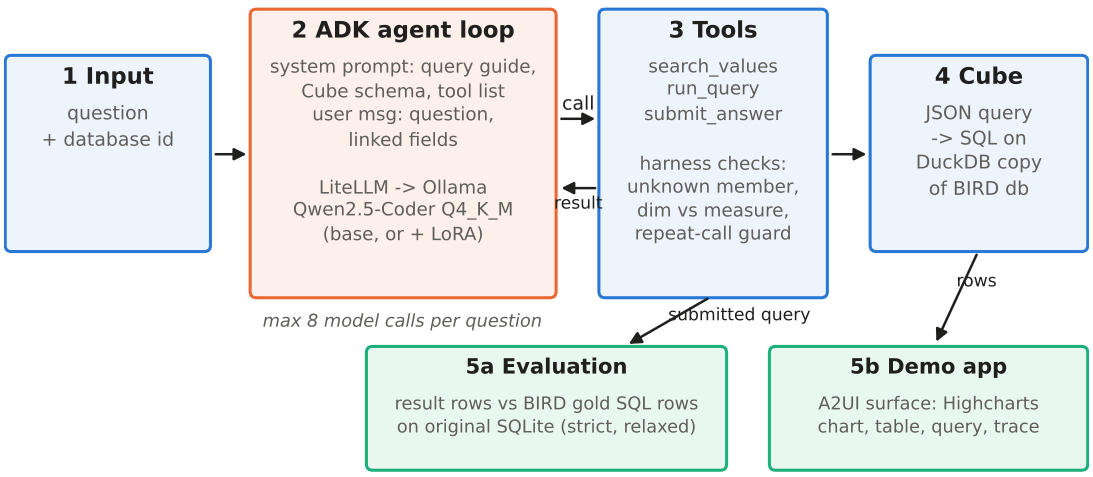

In [2]:
show_figure("fig02_pipeline")

In [3]:
h, l = A.test_run("harness_7b"), A.test_run("lora_7b")
qid = 923
print("QUESTION:", h.loc[qid, "question"])
print("GOLD SQL:", h.loc[qid, "gold_sql"], "\n")
for name, df in [("harness only", h), ("LoRA, full prompt", l)]:
    row = df.loc[qid]
    print(f"--- 7B {name}: {'CORRECT' if row.correct else 'wrong'}, {row.steps} model calls")
    print(A.render_trace(row, 160), "\n")

QUESTION: How many Formula_1 races took place on the circuits in Italy?
GOLD SQL: SELECT COUNT(T2.circuitId) FROM circuits AS T1 INNER JOIN races AS T2 ON T2.circuitID = T1.circuitId WHERE T1.country = 'Italy' 

--- 7B harness only: wrong, 4 model calls
> search_values({"dimension":"circuits.country","text":"Italy"})
  < ["Italy"]
> run_query({"measures":["races.count"],"dimensions":["races.circuitId"],"filters":[{"member":"circuits.country","operator":"equals","values":["Italy"]}]})
  < {"row_count": 3, "rows": [{"races.circuitId": "14", "races.count": "67"}, {"races.circuitId": "21", "races.count": "27"}, {"races.circuitId": "65", "races.count ...
> submit_answer({"dimensions":["races.circuitId"],"filters":[{"member":"circuits.country","operator":"equals","values":["Italy"]}],"measures":["races.count"]})
  < Accepted. 

--- 7B LoRA, full prompt: CORRECT, 2 model calls
> run_query({"measures":["races.count"],"filters":[{"member":"circuits.country","operator":"equals","values":["Italy"

A Cube query is JSON: `measures` (aggregates such as counts and sums), `dimensions` (fields to group by or return),
`filters`, `order` and `limit`. Cube writes the SQL, including the joins, from the schema. This is why the
schema in the prompt matters so much: the model can only use member names that exist there.

## 3. The data

Everything comes from **BIRD** (Li et al., NeurIPS 2023; CC BY-SA 4.0), a text-to-SQL benchmark with real
databases. No database is in more than one split:

* **Test**: all 332 BIRD dev questions on `formula_1` and `student_club`, frozen before any experiment.
* **Harness tuning**: BIRD dev questions on three other databases, used to develop the prompt (Appendix A).
* **LoRA training**: BIRD *train* questions on 58 other databases. Their gold SQL was translated into Cube queries
  by a rule-based translator (`harness/sql2cube.py`) and a pair was kept **only if the Cube result equals the SQL
  result**. Each kept pair was then written out as a full agent conversation in the harness's exact format.

BIRD adds an *evidence hint* to each question (e.g. "full name refers to forename, surname"). A real user would not
type that, so every reported run hides it from the model (`--no-evidence`).

The cell counts the test questions per database and difficulty, and the training pairs.

In [4]:
test = A.test_run("harness_7b")
display(pd.crosstab(test.db_id, test.difficulty, margins=True, margins_name="total"))

train = pd.read_json(ROOT / "training_data" / "verified.jsonl", lines=True)
def cubes_used(q):
    members = q.get("measures", []) + q.get("dimensions", []) + [f["member"] for f in q.get("filters", []) if "member" in f] + list(q.get("order", {}))
    return {m.split(".")[0] for m in members}

print(f"{test.has_join.mean():.0%} of the test questions need a join in the gold SQL")
print(f"{len(train):,} verified training pairs on {train.db_id.nunique()} BIRD train databases; "
      f"{(train.cube_query.apply(cubes_used).str.len() > 1).mean():.0%} of their Cube queries use more than one cube (a join)")

difficulty,challenging,moderate,simple,total
db_id,,,,
formula_1,14,43,117,174
student_club,9,48,101,158
total,23,91,218,332


78% of the test questions need a join in the gold SQL


3,531 verified training pairs on 58 BIRD train databases; 69% of their Cube queries use more than one cube (a join)


One training pair: the question, BIRD's SQL, and the Cube query that gives the same rows.

In [5]:
ex = train.iloc[0]
print("QUESTION:", ex.question)
print("SQL:     ", ex.sql)
print("CUBE:    ", json.dumps(ex.cube_query))
print("ROWS:    ", ex.preview)

QUESTION: What is the total number of households in Arecibo county?
SQL:      SELECT SUM(T1.households) FROM zip_data AS T1 INNER JOIN country AS T2 ON T1.zip_code = T2.zip_code WHERE T2.county = 'ARECIBO'
CUBE:     {"measures": ["zip_data.sum_households"], "filters": [{"member": "country.county", "operator": "equals", "values": ["ARECIBO"]}]}
ROWS:     [{'zip_data.sum_households': '36526'}]


And the start of the schema text the model sees for that training database (the same format is used for the test databases):

In [6]:
print((ROOT / "training_data" / "schemas" / f"{ex.db_id}.txt").read_text()[:900], "...")

cube CBSA
  dim  CBSA.CBSA (number) -- the code of the cbsa officer
  dim  CBSA.CBSA_name (string) -- the name and the position of the cbsa officer
  dim  CBSA.CBSA_type (string) -- the office type of the officer
  meas CBSA.count (count)
cube state
  dim  state.abbreviation (string) -- the abbreviation of the state name
  dim  state.name (string) -- the state name
  meas state.count (count)
cube congress
  dim  congress.cognress_rep_id (string) -- the representative id of congress representatives
  dim  congress.first_name (string) -- the first name of the congress representative
  dim  congress.last_name (string) -- the last name of the congress representative
  dim  congress.CID (string) -- the unique identifier for the congress representative
  dim  congress.party (string) -- the party of the representative
  dim  congress.state (string) -- the state that the representative is from
  ...


The report's Fig. 3 shows how the 8,003 training questions became 3,531 verified pairs:

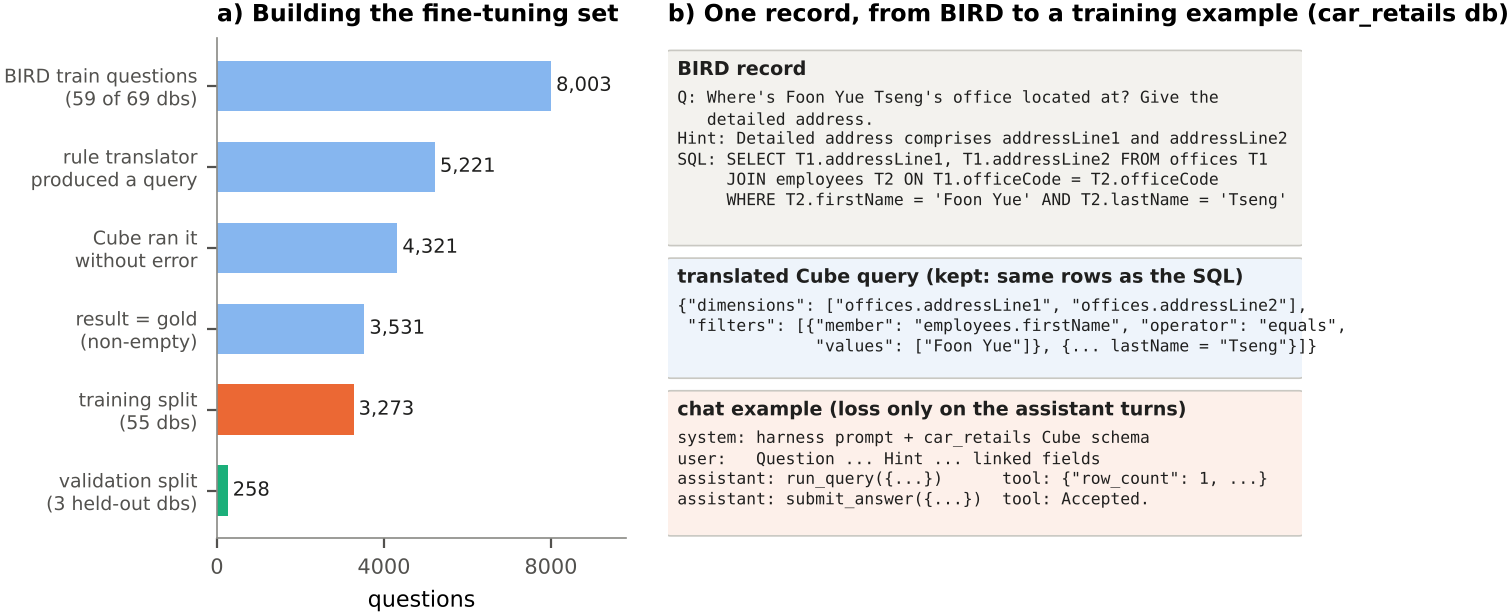

In [7]:
show_figure("fig03_data")

## 4. The compared systems

All systems use the **same harness** (agent, tools and checks; version v4.2, frozen before fine-tuning) and the
same Qwen2.5-Coder model file, 4-bit in Ollama. The names give the adapter and the prompt it was trained and run with.

| System | Adapter | Prompt |
|---|---|---|
| **harness only** (baseline) | none | full: query guide + tool schemas + full database schema |
| **LoRA, full prompt** (proposed) | trained on the 3,531 transcripts | full |
| **LoRA, lean prompt** | trained with the lean prompt | lean: no query guide, no tool schemas, compact schema |
| **noschema LoRA, no schema** | also trained on synthetic questions about the two test schemas | database name only |
| **noschema LoRA, lean prompt** | same adapter | lean |
| **lookup LoRA, full / lean prompt** (extra arms) | retrained to look filter values up (more lookup examples, trained `<tool_call>` tokens) | full / lean |

Each system was run at 7B and 14B. The cell lists the stored run behind each name.

In [8]:
REPORTED = ["harness_7b", "lora_7b", "lean_7b", "noschema_7b", "noschema_lean_7b", "sv3_7b", "lean_sv3_7b",
            "harness_14b", "lora_14b", "lean_14b", "noschema_14b", "noschema_lean_14b", "sv3_14b", "lean_sv3_14b"]
pd.DataFrame([{"system": A.TEST_RUNS[k][1], "stored run": f"results/runs/{A.TEST_RUNS[k][0]}.jsonl.gz"} for k in REPORTED])

,system,stored run
0,7B harness only,results/runs/test_nohint_harness_7b.jsonl.gz
1,"7B LoRA, full prompt",results/runs/test_nohint_lora_7b.jsonl.gz
2,"7B LoRA, lean prompt",results/runs/test_nohint_lean_7b.jsonl.gz
3,"7B noschema LoRA, no schema",results/runs/test_nohint_noschema_7b.jsonl.gz
4,"7B noschema LoRA, lean prompt",results/runs/test_nohint_noschema_lean_prompt_7b.jsonl.gz
5,"7B lookup LoRA, full prompt",results/runs/test_nohint_lora_sv3_nt_7b.jsonl.gz
6,"7B lookup LoRA, lean prompt",results/runs/test_nohint_lean_sv3_7b.jsonl.gz
7,14B harness only,results/runs/test_nohint_harness_14b.jsonl.gz
8,"14B LoRA, full prompt",results/runs/test_nohint_lora_14b.jsonl.gz
9,"14B LoRA, lean prompt",results/runs/test_nohint_lean_14b.jsonl.gz


## 5. How answers are scored

**Execution accuracy**: the submitted Cube query is run and its rows are compared with the rows of the gold SQL
(as sets, column order ignored).

* **Strict** (headline): same rows and the same number of columns.
* **Relaxed**: also accepts extra columns. Cube must return every dimension it sorts by, while SQL can sort by a
  column it does not return, so some correct answers carry one extra column.

The cell shows a question that is correct under relaxed but not strict scoring.

In [9]:
x = l[l.correct_relaxed & ~l.correct].iloc[0]
print("QUESTION:", x.question)
print("GOLD SQL:", x.gold_sql)
print("PREDICTED CUBE QUERY:", json.dumps(x.pred_query))

QUESTION: Who was the driver that got the best lap time in the race No. 348? Give his full name.
GOLD SQL: SELECT T2.forename, T2.surname FROM lapTimes AS T1 INNER JOIN drivers AS T2 ON T2.driverId = T1.driverId WHERE T1.raceId = 348 ORDER BY T1.time ASC LIMIT 1
PREDICTED CUBE QUERY: {"dimensions": ["drivers.forename", "drivers.surname", "lapTimes.milliseconds"], "filters": [{"member": "races.raceId", "operator": "equals", "values": ["348"]}], "limit": 1, "order": {"lapTimes.milliseconds": "asc"}}


The predicted query returns the lap time as well as the name, because it orders by it; the gold SQL orders by the time without returning it.

## 6. Main result: does the LoRA help?

The cell rebuilds the report's Table 5: strict and relaxed accuracy, prompt tokens per question (summed over all
model calls), model calls ("steps"), and model latency per question.

The *p* column is an **exact McNemar test** on strict accuracy against the harness-only system of the same size.
Both systems answer the same 332 questions, so the test only looks at the questions where exactly one of the two is
right (`only_a` vs `only_b`) and asks whether that split could be a coin toss.

In [10]:
ROWS = ["harness_7b", "lora_7b", "lean_7b", "harness_14b", "lora_14b", "lean_14b",
        "sv3_7b", "lean_sv3_7b", "sv3_14b", "lean_sv3_14b"]
t = A.summary_table(ROWS)
t["p vs harness only"] = [None if k.startswith("harness") else A.mcnemar("harness_" + k.split("_")[-1], k)["p"] for k in ROWS]
table5 = t[["run", "strict", "relaxed", "prompt_tokens", "steps", "latency_s", "latency_median_s", "latency_p90_s", "p vs harness only"]]
table5.style.format({"strict": "{:.1f}", "relaxed": "{:.1f}", "prompt_tokens": "{:,.0f}", "steps": "{:.1f}",
                     "latency_s": "{:.1f}", "latency_median_s": "{:.1f}", "latency_p90_s": "{:.1f}",
                     "p vs harness only": lambda p: "" if pd.isna(p) else f"{p:.0e}"}).hide(axis="index")

run,strict,relaxed,prompt_tokens,steps,latency_s,latency_median_s,latency_p90_s,p vs harness only
7B harness only,21.4,27.7,"15,929",4.1,3.5,2.3,6.8,
"7B LoRA, full prompt",36.7,40.7,"7,672",2.1,1.3,1.2,1.7,5e-08
"7B LoRA, lean prompt",34.6,36.7,"3,242",2.2,1.4,1.2,1.5,3e-06
14B harness only,27.4,35.8,"11,952",3.2,4.6,3.8,7.0,
"14B LoRA, full prompt",40.7,45.5,"7,344",2.0,2.4,2.3,3.2,2e-07
"14B LoRA, lean prompt",40.1,46.1,"2,988",2.0,2.3,2.2,3.3,1e-06
"7B lookup LoRA, full prompt",41.9,47.6,"12,204",3.3,1.7,1.5,2.3,2e-13
"7B lookup LoRA, lean prompt",33.4,37.3,"5,813",3.8,1.8,1.4,3.2,9e-06
"14B lookup LoRA, full prompt",44.9,48.8,"11,638",3.1,2.7,2.4,3.8,4e-11
"14B lookup LoRA, lean prompt",46.1,52.1,"4,728",3.2,2.7,2.4,4.0,9e-12


The paired counts behind the two headline comparisons:

In [11]:
pd.DataFrame([A.mcnemar("harness_7b", "lora_7b"), A.mcnemar("harness_14b", "lora_14b"),
              A.mcnemar("harness_14b", "lora_7b")]).assign(p=lambda d: d.p.map("{:.1e}".format))

,a,b,only_a,only_b,p,n
0,harness_7b,lora_7b,19,70,5.0e-08,332
1,harness_14b,lora_14b,14,58,1.6e-07,332
2,harness_14b,lora_7b,26,57,8.8e-04,332


**How to read it.** The LoRA adds about 15 points of strict accuracy at 7B (21.4 → 36.7) and 13 at 14B
(27.4 → 40.7), with *p* far below 0.05. The fine-tuned 7B even beats the 14B harness-only model (last row: 14B
harness only is right on fewer of the disputed questions). It also needs about half the model calls and half the
latency, since it gets the query right in fewer tries.

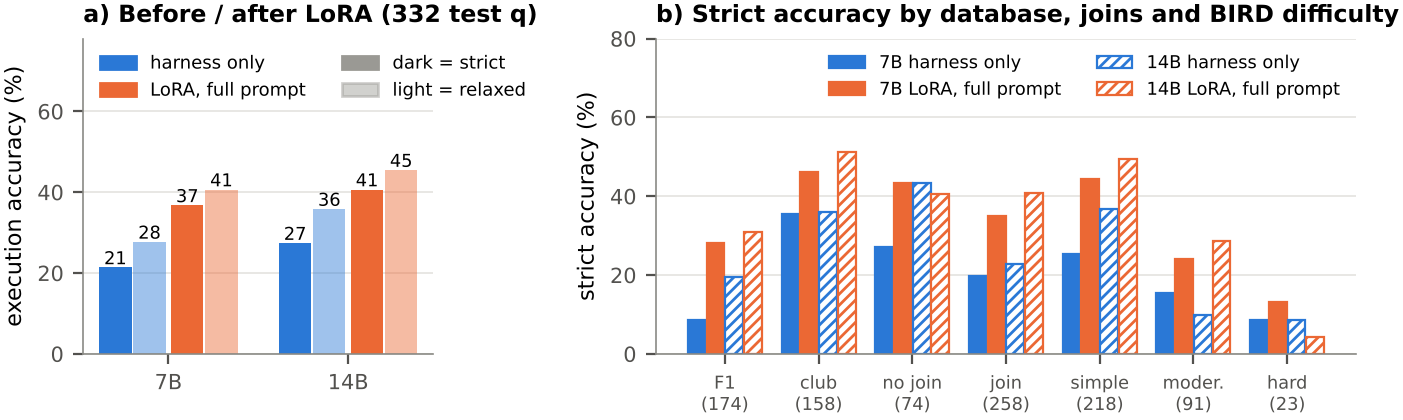

In [12]:
show_figure("fig07_main")

## 7. Where the gain comes from

Strict accuracy of the four main systems split by database, by whether the gold SQL needs a join, and by BIRD's
difficulty label.

In [13]:
rows = []
for run in A.MAIN_ARMS:
    for by in ["db_id", "has_join", "difficulty"]:
        for k, v in A.breakdown(run, by).items():
            rows.append({"system": A.TEST_RUNS[run][1], "group": f"{by} = {k}", "strict": v})
pd.DataFrame(rows).pivot(index="group", columns="system", values="strict")[[A.TEST_RUNS[r][1] for r in A.MAIN_ARMS]].round(1)

system,7B harness only,"7B LoRA, full prompt",14B harness only,"14B LoRA, full prompt"
group,,,,
db_id = formula_1,8.6,28.2,19.5,31.0
db_id = student_club,35.4,46.2,36.1,51.3
difficulty = challenging,8.7,13.0,8.7,4.3
difficulty = moderate,15.4,24.2,9.9,28.6
difficulty = simple,25.2,44.5,36.7,49.5
has_join = False,27.0,43.2,43.2,40.5
has_join = True,19.8,34.9,22.9,40.7


The gain holds on both databases. At 7B it holds with and without a join; at 14B it comes entirely from questions
that need a join (22.9 → 40.7), where the adapter has learned which cube a field lives in and lets Cube build the
join. Most training queries use more than one cube (section 3).

## 8. Moving the prompt into the weights

The full prompt is long (about 8–16k tokens per question over all calls). Can the adapter learn what the prompt
spells out, so the prompt can be shorter? The cell compares the full-prompt LoRA with:

* the **LoRA, lean prompt** (trained and run without the query guide and tool schemas, compact schema);
* the **noschema LoRA** run with no schema at all, and with the lean prompt;
* a **control**: the full-prompt LoRA given the lean prompt *without* retraining (7B).

In [14]:
OFF = ["lora_7b", "lean_7b", "noschema_7b", "noschema_lean_7b", "lora_on_lean_7b",
       "lora_14b", "lean_14b", "noschema_14b", "noschema_lean_14b"]
o = A.summary_table(OFF)
o["p vs LoRA, full prompt"] = [None if k.startswith("lora_") and "lean" not in k else A.mcnemar("lora_" + k.split("_")[-1], k)["p"] for k in OFF]
o[["run", "strict", "relaxed", "prompt_tokens", "p vs LoRA, full prompt"]].style.format(
    {"strict": "{:.1f}", "relaxed": "{:.1f}", "prompt_tokens": "{:,.0f}",
     "p vs LoRA, full prompt": lambda p: "" if pd.isna(p) else f"{p:.2g}"}).hide(axis="index")

run,strict,relaxed,prompt_tokens,"p vs LoRA, full prompt"
"7B LoRA, full prompt",36.7,40.7,"7,672",
"7B LoRA, lean prompt",34.6,36.7,"3,242",0.3
"7B noschema LoRA, no schema",18.1,19.9,"1,616",1e-12
"7B noschema LoRA, lean prompt",37.0,39.2,"3,201",1
"7B LoRA (full-prompt trained), lean prompt",0.0,0.0,"5,429",3.8e-37
"14B LoRA, full prompt",40.7,45.5,"7,344",
"14B LoRA, lean prompt",40.1,46.1,"2,988",0.83
"14B noschema LoRA, no schema",24.7,25.6,"1,140",7.3e-11
"14B noschema LoRA, lean prompt",41.0,45.5,"2,929",1


**How to read it.** The lean prompt costs about 40% of the full prompt's tokens and loses only about 2 points at
7B and less than 1 at 14B, neither significant. Without any schema, accuracy falls by 16–19 points: the model
invents field names (count below). With the short schema back, the noschema LoRA is level with the full-prompt
LoRA. The control scores 0%: an adapter only works with the prompt it was trained on.

In [15]:
for k in ["noschema_14b", "lean_14b"]:
    df = A.test_run(k)
    n = df.trace.apply(lambda t: any("Unknown member" in (s.get("content") or "") for s in t or [])).sum()
    print(f"{A.TEST_RUNS[k][1]}: an 'unknown member' error in {n} of {len(df)} questions")

14B noschema LoRA, no schema: an 'unknown member' error in 114 of 332 questions
14B LoRA, lean prompt: an 'unknown member' error in 1 of 332 questions


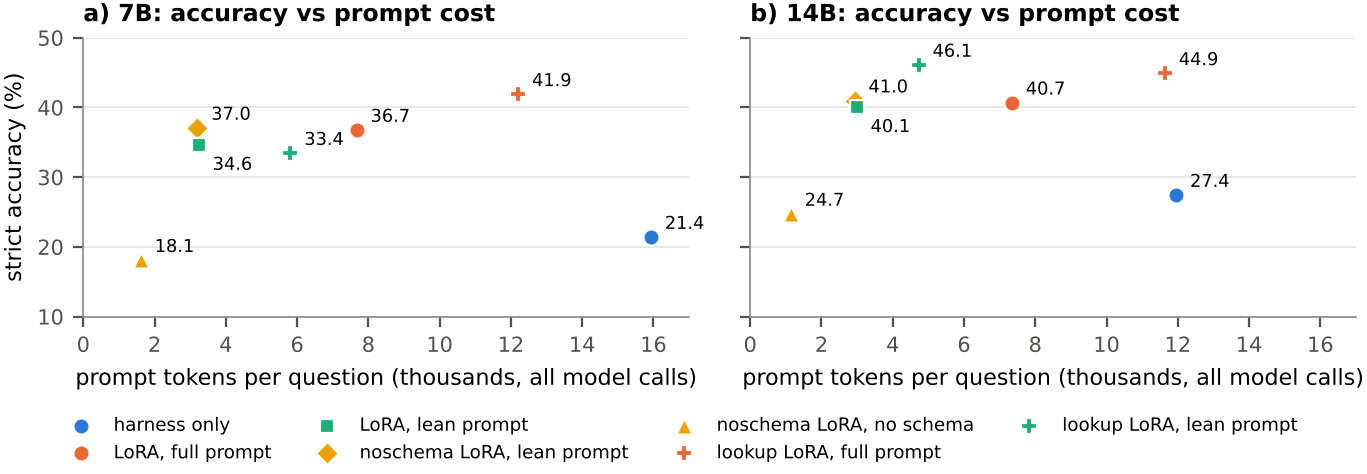

In [16]:
show_figure("fig08_offload")

## 9. How the models use the tools

Per question: `search_values` calls (lookups), `run_query` calls (drafts), calls the harness or Cube turned back
(rejected), the share of tool calls the model wrote as plain text instead of in `<tool_call>` tags (the harness
parses those with a text fallback), and the share of answers whose last draft returned no rows (empty answers).
This is the report's Table 6.

In [17]:
TOOLS = ["harness_7b", "lora_7b", "harness_14b", "lora_14b", "sv3_7b", "lean_sv3_7b", "sv3_14b", "lean_sv3_14b"]
A.tool_table(TOOLS).set_index("run")[["search_values_per_q", "run_query_per_q", "rejected_per_q", "text_calls_pct", "empty_answer_pct"]].round(2)

,search_values_per_q,run_query_per_q,rejected_per_q,text_calls_pct,empty_answer_pct
run,,,,,
7B harness only,1.97,0.69,1.09,15.99,2.41
"7B LoRA, full prompt",0.01,1.09,0.11,0.14,12.95
14B harness only,0.95,0.95,0.14,53.67,10.24
"14B LoRA, full prompt",0.00,0.97,0.00,100.00,13.25
"7B lookup LoRA, full prompt",1.05,1.18,0.27,0.00,4.52
"7B lookup LoRA, lean prompt",1.28,1.50,0.94,0.24,6.33
"14B lookup LoRA, full prompt",1.04,1.09,0.12,0.00,3.92
"14B lookup LoRA, lean prompt",1.08,1.12,0.20,0.00,5.72


**How to read it.** The first adapters almost never look values up (0.01 and 0.00 lookups per question): only
22% of their training transcripts had a lookup. So when a filter value is spelled differently in the data, they
get zero rows and submit anyway (13% empty answers). The **lookup LoRAs** were retrained with a lookup before
every text filter and with the `<tool_call>` tokens trained (they are untrained in the base model). They look
values up about once per question, cut empty answers to 4–6%, and gain 5.2 points at 7B and 4.2 at 14B:

In [18]:
pd.DataFrame([A.mcnemar("lora_7b", "sv3_7b"), A.mcnemar("lora_14b", "sv3_14b"),
              A.mcnemar("lean_14b", "lean_sv3_14b"), A.mcnemar("lean_7b", "lean_sv3_7b")]).assign(p=lambda d: d.p.map("{:.3f}".format))

,a,b,only_a,only_b,p,n
0,lora_7b,sv3_7b,15,32,0.019,332
1,lora_14b,sv3_14b,9,23,0.020,332
2,lean_14b,lean_sv3_14b,7,27,0.001,332
3,lean_7b,lean_sv3_7b,32,28,0.699,332


The 14B lookup LoRA with the lean prompt is the best system of the study (46.1% strict at 4.7k prompt tokens).
The 7B one with the lean prompt loops between lookups and drafts and does not improve; it is kept as a negative
result. Real traces from the report:

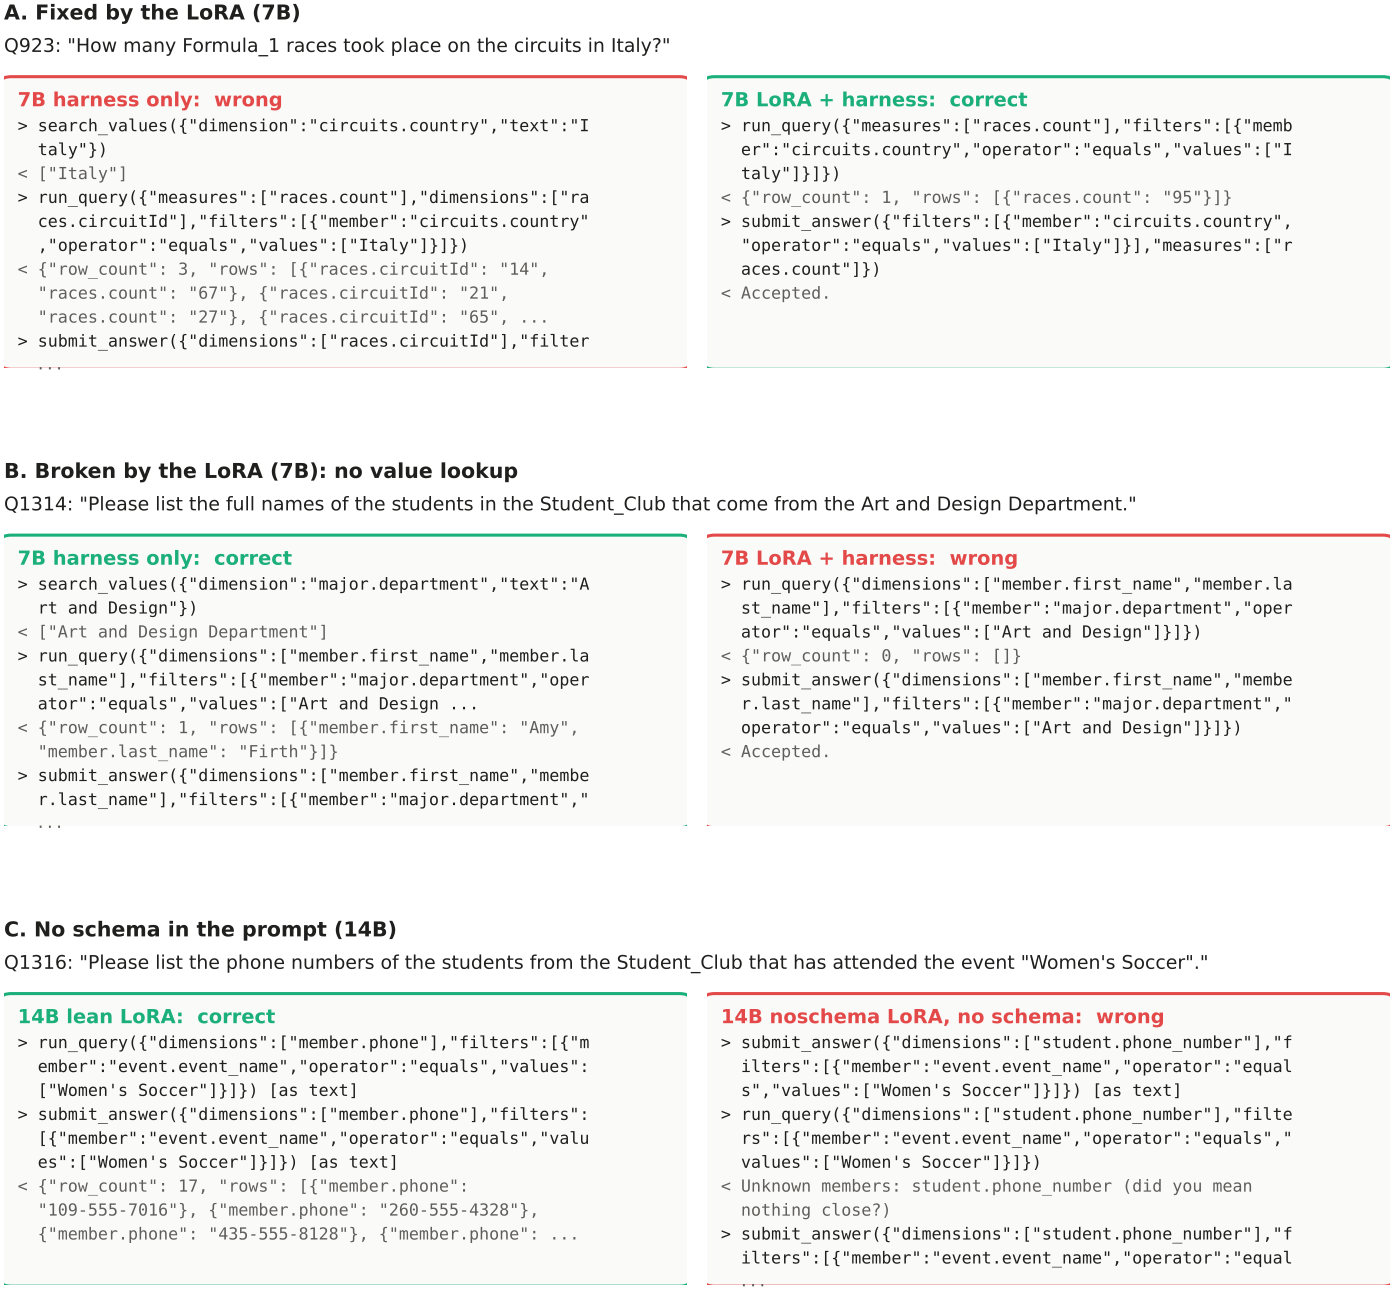

In [19]:
show_figure("fig09_outputs")

## 10. Training curves

Each adapter is a QLoRA (rank 16) on Qwen2.5-Coder-Instruct, trained for 2 epochs on the transcripts, with the
loss only on the model's own turns. The cell lists each run's settings and its validation loss at the start and
every half epoch (from the stored Trainer logs). `train_examples` counts only the transcripts that fit in
`max_len` tokens; the 14B fits 16 GB of GPU memory only at 4,096 tokens, so it saw about 10% fewer examples. The
noschema adapters also see the synthetic questions about the test schemas.

In [20]:
pd.DataFrame([{"run": n, **{k: A.training_log(n)["config"][k] for k in ["base", "max_len", "train_examples", "val_examples"]},
               "hours": round(A.training_log(n)["runtime_h"], 1),
               "validation loss": [round(x, 3) for x in A.training_log(n)["eval"]["eval_loss"]]}
              for n in A.TRAIN_LOGS]).set_index("run")

,base,max_len,train_examples,val_examples,hours,validation loss
run,,,,,,
lora_full_7b,Qwen/Qwen2.5-Coder-7B-Instruct,8192,2929,258,5.3,"[1.0, 0.275, 0.274, 0.274, 0.274]"
lora_full_14b,Qwen/Qwen2.5-Coder-14B-Instruct,4096,2621,139,9.0,"[0.786, 0.273, 0.271, 0.271, 0.271]"
lora_lean_7b,Qwen/Qwen2.5-Coder-7B-Instruct,8192,2929,258,2.0,"[1.465, 0.276, 0.273, 0.274, 0.274]"
lora_lean_14b,Qwen/Qwen2.5-Coder-14B-Instruct,4096,2621,139,2.9,"[1.06, 0.275, 0.272, 0.272, 0.272]"
lora_noschema_7b,Qwen/Qwen2.5-Coder-7B-Instruct,8192,4164,323,2.5,"[1.495, 0.286, 0.282, 0.281, 0.281]"
lora_noschema_14b,Qwen/Qwen2.5-Coder-14B-Instruct,4096,3856,204,3.7,"[1.146, 0.288, 0.285, 0.285, 0.284]"


The loss drops within the first quarter epoch and then flattens, so 2 epochs are enough:

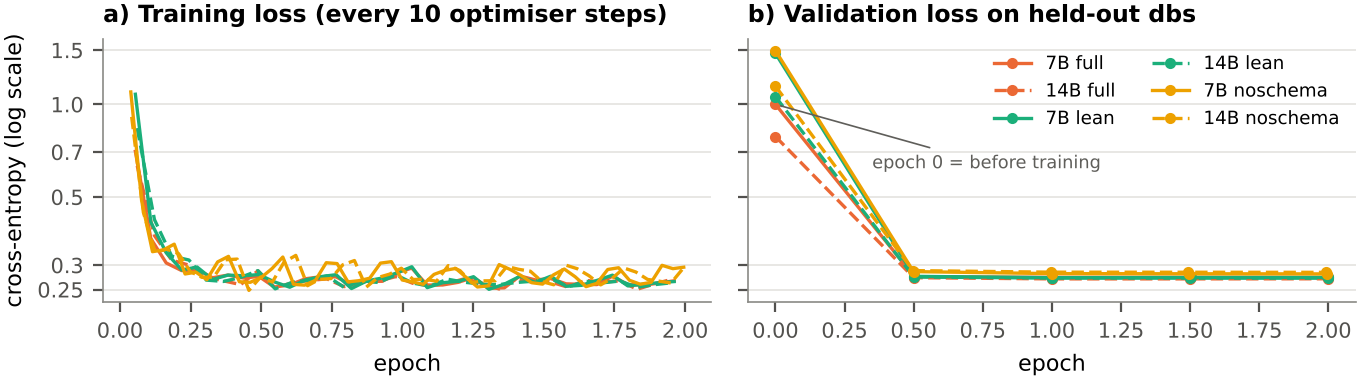

In [21]:
show_figure("fig06_training")

## 11. What goes wrong

Each wrong answer gets one category from a set of rules (`analysis.error_category`, applied in order). The rules
compare the predicted Cube query with the gold SQL, so they describe *where* the answer differs, not *why* the model
erred. "Needs SQL Cube cannot express" marks questions that no Cube query can answer (nested queries, CASE
arithmetic, string slicing): about 30% of the test set, a ceiling for every system.

In [22]:
pd.DataFrame({A.TEST_RUNS[r][1]: A.error_counts(r) for r in A.MAIN_ARMS})

,7B harness only,"7B LoRA, full prompt",14B harness only,"14B LoRA, full prompt"
No valid answer (error / call limit),45,4,20,4
Needs SQL Cube cannot express,56,56,59,55
Extra columns only,21,13,28,16
Wrong filter value,64,50,48,39
Aggregation missing or wrong,8,5,8,5
Wrong columns returned,16,21,29,23
Ranking / limit missing,4,1,1,1
Wrong field or join path,47,60,48,54


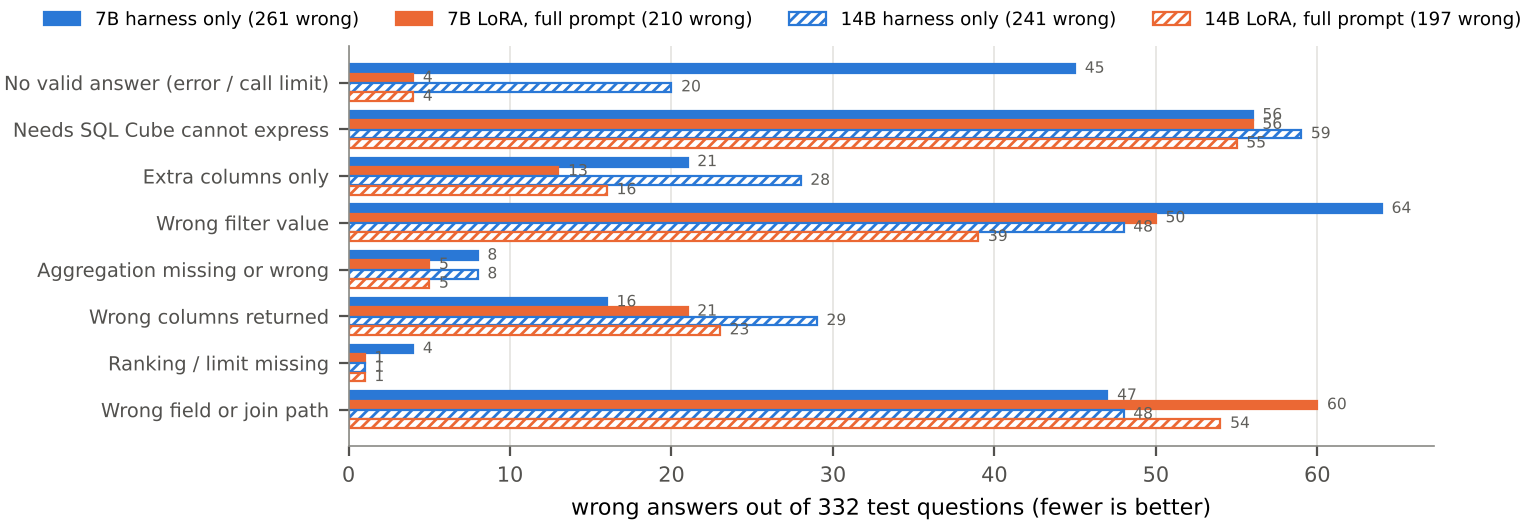

In [23]:
show_figure("fig10_errors")

So that the report does not show only chosen cases, here are five LoRA errors drawn at random (fixed seed):

In [24]:
for qid, row in l[~l.correct].sample(5, random_state=0).iterrows():
    print(f"Q{qid} [{A.error_category(row)}] {row.question}")
    print("   predicted:", json.dumps(row.pred_query)[:200])
    print("   gold SQL: ", row.gold_sql[:200], "\n")

Q865 [Wrong columns returned] For all the drivers who finished the game in race No. 592, who is the oldest?
   predicted: {"dimensions": ["drivers.forename", "drivers.surname", "drivers.dob"], "filters": [{"member": "results.raceId", "operator": "equals", "values": ["592"]}], "limit": 1, "order": {"drivers.dob": "asc"}}
   gold SQL:  SELECT T1.forename, T1.surname FROM drivers AS T1 INNER JOIN results AS T2 ON T2.driverId = T1.driverId WHERE T2.raceId = 592 AND T2.time IS NOT NULL AND T1.dob IS NOT NULL ORDER BY T1.dob ASC LIMIT 1 

Q960 [Wrong field or join path] What is the average of fastest lap speed in the 2009 Spanish Grand Prix race?
   predicted: {"filters": [{"member": "races.year", "operator": "equals", "values": ["2009"]}, {"member": "circuits.name", "operator": "equals", "values": ["Spanish Grand Prix"]}], "measures": ["results.avg_fastest
   gold SQL:  SELECT AVG(T1.fastestLapSpeed) FROM results AS T1 INNER JOIN races AS T2 on T1.raceId = T2.raceId WHERE T2.year = 2009 AND

## Appendix A. How the harness was developed

The harness-only baseline is not a weak straw man: its prompt and tools went through five versions, tuned on
three *other* databases. These development runs **kept BIRD's hint** (the setting used while building the harness),
so they are not comparable with the results above; they show only how far prompt engineering got before the
harness was frozen (v4.2).

In [25]:
dev = {**{f"test, {k.split('_')[2]}": A.summary(A.test_run(k)) for k in ["hint_harness_v1_7b", "hint_harness_v2_7b"]},
       "test, v4.2": A.summary(A.test_run("hint_harness_7b")),
       **{f"tuning (120 q), {k}": A.summary(A.load_run(v)) for k, v in A.TUNE_RUNS.items()},
       **{f"tuning (363 q), {k}": A.summary(A.load_run(v)) for k, v in A.TUNE363_RUNS.items()}}
pd.DataFrame(dev).T[["n", "strict", "relaxed", "steps"]].round(1)

,n,strict,relaxed,steps
"test, v1",332.0,13.3,26.8,3.6
"test, v2",332.0,20.5,34.3,3.5
"test, v4.2",332.0,27.7,34.0,4.0
"tuning (120 q), v2",120.0,22.5,28.3,3.3
"tuning (120 q), v3",120.0,23.3,27.5,3.4
"tuning (120 q), v4",120.0,22.5,29.2,3.6
"tuning (120 q), v4.1",120.0,24.2,30.8,3.6
"tuning (363 q), v3 7B",363.0,26.2,33.6,3.4
"tuning (363 q), v4.2 7B",363.0,32.0,35.3,3.8
"tuning (363 q), v4.2 14B",363.0,38.8,47.9,2.7


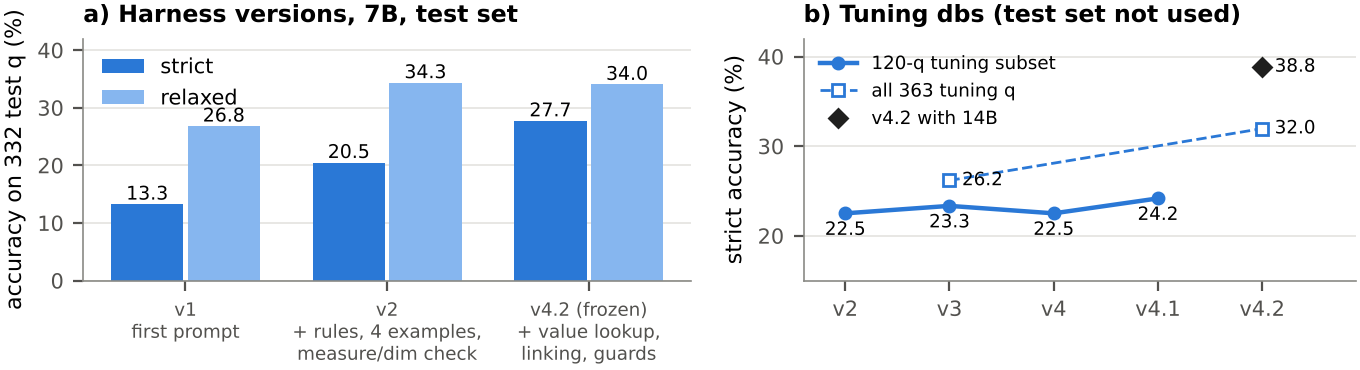

In [26]:
show_figure("fig04_harness_versions")

## Appendix B. Commands that produced the stored runs

Not run here: they need BIRD downloaded, Cube on port 4000, Ollama, and a 16 GB GPU for training (one evaluation
takes 10–25 minutes; training about 5 h at 7B and 9 h at 14B on an RTX 5070 Ti). The README has the full setup.

In [27]:
STEPS = '''
# data: BIRD -> DuckDB -> Cube models; training pairs
python scripts/download_bird.py
python scripts/build_duckdb.py --bird-dir data/bird --out data/bird.duckdb --db formula_1 --db student_club
python scripts/gen_cube_models.py --bird-dir data/bird --out cube/model --db formula_1 --db student_club
python scripts/make_sft.py --data training_data --out data/sft

# harness only (7B; 14B: qwen2.5-coder:14b)
python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen2.5-coder:7b --setup harness-v4.2-7b-nohint --out runs/test_nohint_harness_7b.jsonl

# LoRA, full prompt (14B: Qwen2.5-Coder-14B-Instruct, --max-len 4096)
python scripts/train_lora.py --base Qwen/Qwen2.5-Coder-7B-Instruct --out lora/qwen7b
python scripts/export_ollama.py --base Qwen/Qwen2.5-Coder-7B-Instruct --adapter lora/qwen7b/final --ollama-base qwen2.5-coder:7b --name qwen7b-cube-lora
python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen7b-cube-lora --setup lora-v4.2-7b-nohint --out runs/test_nohint_lora_7b.jsonl

# LoRA, lean prompt and noschema LoRA
python scripts/make_sft.py --data training_data --profile lean --out data/sft_lean
python scripts/synth_schema_qa.py --db formula_1 --n 800 --db student_club --n 500 --out data/synth/synth.jsonl --audit
python scripts/make_sft.py --data training_data --profile noschema --synthetic data/synth/synth.jsonl --out data/sft_noschema
python -m harness.evaluate ... --profile lean --model ollama_chat/qwen7b-cube-lean

# lookup LoRA (details: docs/README_technical.md)
python scripts/make_sft.py --data training_data_sv3 --out data/sft_sv3
python scripts/train_lora.py --base Qwen/Qwen2.5-Coder-7B-Instruct --data data/sft_sv3 --out lora/qwen7b-sv3 --train-tokens "<tool_call>,</tool_call>"
'''
print(STEPS.strip())

# data: BIRD -> DuckDB -> Cube models; training pairs
python scripts/download_bird.py
python scripts/build_duckdb.py --bird-dir data/bird --out data/bird.duckdb --db formula_1 --db student_club
python scripts/gen_cube_models.py --bird-dir data/bird --out cube/model --db formula_1 --db student_club
python scripts/make_sft.py --data training_data --out data/sft

# harness only (7B; 14B: qwen2.5-coder:14b)
python -m harness.evaluate --db formula_1 --db student_club --ids-file splits/test_ids.json --no-evidence --model ollama_chat/qwen2.5-coder:7b --setup harness-v4.2-7b-nohint --out runs/test_nohint_harness_7b.jsonl

# LoRA, full prompt (14B: Qwen2.5-Coder-14B-Instruct, --max-len 4096)
python scripts/train_lora.py --base Qwen/Qwen2.5-Coder-7B-Instruct --out lora/qwen7b
python scripts/export_ollama.py --base Qwen/Qwen2.5-Coder-7B-Instruct --adapter lora/qwen7b/final --ollama-base qwen2.5-coder:7b --name qwen7b-cube-lora
python -m harness.evaluate --db formula_1 --db student_club --ids-file

After a new run, gzip its output into `results/runs/` under the file name used in `report/analysis.py` and run this notebook again.